# Task 1: Load and understand the dataset

In [4]:
#load liabraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder, MinMaxScaler
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report

In [5]:
import os

print(os.getcwd())
print(os.listdir("data"))

C:\Users\Fahad\OneDrive\Desktop\GITHUB\AI-Adoption-Analysis
['ai_adoption_data.xlsx']


In [6]:
#import data
AI_df = pd.read_excel("data/ai_adoption_data.xlsx")

AI_df.head()

,country,industry,ai_tool,adoption_rate,daily_active_users,year,user_feedback,age_group,company_size
0,USA,Technology,ChatGPT,40.45,2461,2023,YyvLXOFyevRMSvJtkXodLvgejiqQNvSOZfeeJASDOVTxwm...,35-44,Startup
1,France,Manufacturing,Midjourney,35.72,8496,2024,AdFVhenjthYSKJNzxzfaGQk wLnjRCgrHTyfXQEFjFJCMO...,18-24,Enterprise
2,Australia,Transportation,ChatGPT,13.47,8641,2024,zgNPmXBICRNbpjpTqIUWmMTeTYsInDNtAmzuxpDvcUZEAi...,45-54,Startup
3,UK,Manufacturing,ChatGPT,48.46,3488,2023,LxeKzQFbPvhxXUSgPVlLLJ pUFaicjCgiMtAmsTjovkrdE...,45-54,Enterprise
4,UK,Agriculture,Stable Diffusion,34.06,1124,2024,IOQtQoSKdSmiXRsUKpjXjXZgQohymFkVUvOASXlEnVsIOS...,45-54,SME


In [ ]:
AI_df

In [4]:
AI_df.head(11)

,country,industry,ai_tool,adoption_rate,daily_active_users,year,user_feedback,age_group,company_size
0,USA,Technology,ChatGPT,40.45,2461,2023,YyvLXOFyevRMSvJtkXodLvgejiqQNvSOZfeeJASDOVTxwm...,35-44,Startup
1,France,Manufacturing,Midjourney,35.72,8496,2024,AdFVhenjthYSKJNzxzfaGQk wLnjRCgrHTyfXQEFjFJCMO...,18-24,Enterprise
2,Australia,Transportation,ChatGPT,13.47,8641,2024,zgNPmXBICRNbpjpTqIUWmMTeTYsInDNtAmzuxpDvcUZEAi...,45-54,Startup
3,UK,Manufacturing,ChatGPT,48.46,3488,2023,LxeKzQFbPvhxXUSgPVlLLJ pUFaicjCgiMtAmsTjovkrdE...,45-54,Enterprise
4,UK,Agriculture,Stable Diffusion,34.06,1124,2024,IOQtQoSKdSmiXRsUKpjXjXZgQohymFkVUvOASXlEnVsIOS...,45-54,SME
5,Brazil,Education,Midjourney,64.54,3267,2024,PDkHPYQGOo XqLNwpEsZlbubUVBUDBujoPCWEDoCtcwzKX...,55+,Startup
6,USA,Healthcare,Bard,81.83,4265,2023,VXo RcPqLBqywVUcwrpjmTha FxLtebijbOiZMEIYqkLEK...,35-44,Enterprise
7,Australia,Education,ChatGPT,20.85,5940,2023,MCVWNxfkdvijPwFleHKDKJTIexXAzweDWyBGDQVcOrfAsn...,25-34,Enterprise
8,China,Retail,Midjourney,39.90,613,2024,JJyYjvZPWunxapLpTfaampdgLFquyzjJELCEQfNnZLtXn...,55+,SME
9,USA,Agriculture,Midjourney,20.53,8310,2023,BmKCEuMhGTktndFlwMDIq UVbeFeqlnYXmRypfMgBwuG c...,35-44,Startup


In [5]:
AI_df.tail(11)

,country,industry,ai_tool,adoption_rate,daily_active_users,year,user_feedback,age_group,company_size
144989,Australia,Manufacturing,Midjourney,87.38,7249,2024,DtlxQdJimAPwpHWITHBONcDjGTjArtsJgeDN YgGswswFN...,45-54,SME
144990,USA,Technology,Stable Diffusion,30.58,8297,2024,nkATfOEMvPzqTMKvSkGFrPRDVnpMsLTM APzaNysPetNik...,18-24,Enterprise
144991,South Korea,Education,Midjourney,16.51,130,2024,PnjJnr dRqzEFLRbkHzKIEMA JySivgXbRoQifZbfOqkXz...,25-34,SME
144992,UK,Transportation,Midjourney,98.94,4373,2024,INObQzmd RgDtsZUlViYAYdhpvRDAUXouympYlNsbCCkCe...,25-34,Enterprise
144993,Germany,Retail,Stable Diffusion,85.08,4221,2024,HLPtcjnPARVGqeBtZdQbtjSGgnVDdGFhrUkSMzDyXybEwb...,35-44,Startup
144994,Germany,Retail,Midjourney,88.81,8910,2024,GBQgYYRvWTqZMftupnt cZ XNROkgHaeXjFdMCmYStKiBa...,25-34,Enterprise
144995,Australia,Agriculture,Midjourney,86.93,7921,2023,PxWkyTVwSNPoTXjsKzjbAFEfyJ MdgY CXjvSrkkHOTGcb...,18-24,SME
144996,Germany,Education,Midjourney,51.99,6301,2024,PtOmfGyWyZueDERRioCvbNgXomcpNNLFUjRuMEqeMrqR L...,45-54,SME
144997,USA,Finance,Stable Diffusion,47.35,4726,2023,VQuOdOKjRhchmEFrzvGlqsGOc fbTXzuzQzswt pZTCmhx...,45-54,Startup
144998,USA,Retail,ChatGPT,31.87,2481,2024,IRFOudTsoPrlrKypvToOx llYkLoLqrw EMHOtyAKmqXq...,25-34,Enterprise


In [6]:
#Find the number of rows.
total_rows = AI_df.shape[0]
print(f"Rows:{total_rows}")

#Find the number of columns
total_cols = AI_df.shape[1]
print(f"Columns:{total_cols}")


Rows:145000
Columns:9


In [7]:
#Display column names.
print(list(AI_df))

['country', 'industry', 'ai_tool', 'adoption_rate', 'daily_active_users', 'year', 'user_feedback', 'age_group', 'company_size']


In [8]:
#Display data types.
print(AI_df[["country", "industry", "ai_tool",'adoption_rate', 'daily_active_users', 'year', 'user_feedback', 'age_group', "company_size"]].dtypes)

country                object
industry               object
ai_tool                object
adoption_rate         float64
daily_active_users      int64
year                    int64
user_feedback          object
age_group              object
company_size           object
dtype: object


In [9]:
#Generate descriptive statistics for numeric columns.
descriptive_statistics = AI_df.describe()  
print("--------------Discriptive analysis------------")
print(descriptive_statistics)

--------------Discriptive analysis------------
       adoption_rate  daily_active_users           year
count  145000.000000       145000.000000  145000.000000
mean       49.873025         5039.302683    2023.703117
std        28.842523         2858.124918       0.456886
min         0.000000          100.000000    2023.000000
25%        24.930000         2566.000000    2023.000000
50%        49.760000         5036.000000    2024.000000
75%        74.840000         7515.000000    2024.000000
max       100.000000         9999.000000    2024.000000


In [10]:
#Generate frequency summaries for categorical columns.
Numeric_statistics = AI_df.describe(include='O')  
print("--------------Numeric analysis------------")
print(Numeric_statistics)

--------------Numeric analysis------------
          country       industry  ai_tool  \
count      145000         145000   145000   
unique         10              8        5   
top     Australia  Manufacturing  ChatGPT   
freq        14723          18267    58045   

                                            user_feedback age_group  \
count                                              145000    145000   
unique                                             145000         5   
top     YyvLXOFyevRMSvJtkXodLvgejiqQNvSOZfeeJASDOVTxwm...       55+   
freq                                                    1     29424   

       company_size  
count        145000  
unique            3  
top         Startup  
freq          48601  


# Task 2: Build a data dictionary

In [11]:
# Create a data dictionary

data_dictionary = pd.DataFrame({
    "Column": [
        "country",
        "industry",
        "ai_tool",
        "adoption_rate",
        "daily_active_users",
        "year",
        "user_feedback",
        "age_group",
        "company_size"
    ],

    "Type": [
        "Categorical",
        "Categorical",
        "Categorical",
        "Numeric",
        "Numeric",
        "Categorical/Time",
        "Text",
        "Ordered Category",
        "Categorical"
    ],

    "Meaning": [
        "Country",
        "Industry",
        "AI platform",
        "Adoption percentage",
        "Daily active users",
        "Year",
        "User feedback",
        "User age group",
        "Company size"
    ],

    "Analysis Role": [
        "Predictor / Group",
        "Predictor / Group",
        "Predictor / Group",
        "Main Outcome",
        "Predictor / Outcome",
        "Time Comparison",
        "Exclude from Analysis",
        "Predictor / Group",
        "Predictor / Group"
    ]
})

data_dictionary

,Column,Type,Meaning,Analysis Role
0,country,Categorical,Country,Predictor / Group
1,industry,Categorical,Industry,Predictor / Group
2,ai_tool,Categorical,AI platform,Predictor / Group
3,adoption_rate,Numeric,Adoption percentage,Main Outcome
4,daily_active_users,Numeric,Daily active users,Predictor / Outcome
5,year,Categorical/Time,Year,Time Comparison
6,user_feedback,Text,User feedback,Exclude from Analysis
7,age_group,Ordered Category,User age group,Predictor / Group
8,company_size,Categorical,Company size,Predictor / Group


# Task 3: Data-quality assessment

In [12]:
#Missing values in every column.

AI_df.isnull().sum()

country               0
industry              0
ai_tool               0
adoption_rate         0
daily_active_users    0
year                  0
user_feedback         0
age_group             0
company_size          0
dtype: int64

In [13]:
AI_df.duplicated().sum()

0

In [14]:
#Number of unique values in each column.

unique_countries = AI_df["country"].unique()
print (f"unique counties: {len(unique_countries)}")
print(f"List of countries: {unique_countries}")

unique counties: 10
List of countries: ['USA' 'France' 'Australia' 'UK' 'Brazil' 'China' 'Canada' 'South Korea'
 'India' 'Germany']


In [15]:
#Number of unique values in each column.
unique_industry = AI_df["industry"].unique()
print (f"unique industry: {len(unique_industry)}")
print(f"List of industry: {unique_industry}")

unique industry: 8
List of industry: ['Technology' 'Manufacturing' 'Transportation' 'Agriculture' 'Education'
 'Healthcare' 'Retail' 'Finance']


In [16]:
#Number of unique values in each column.
unique_ai_tool = AI_df["ai_tool"].unique()
print (f"unique ai_tool: {len(unique_ai_tool)}")
print(f"List of ai_tool: {unique_ai_tool}")

unique ai_tool: 5
List of ai_tool: ['ChatGPT' 'Midjourney' 'Stable Diffusion' 'Bard' 'Claude']


In [17]:
#Number of unique values in each column.
unique_adoption_rate = AI_df["adoption_rate"].unique()
print (f"unique adoption_rate: {len(unique_adoption_rate)}")
print(f"List of adoption_rate: {unique_adoption_rate}")

unique adoption_rate: 10001
List of adoption_rate: [40.45 35.72 13.47 ... 14.71  3.   31.99]


In [18]:
#Number of unique values in each column.
unique_daily_active_users = AI_df["daily_active_users"].unique()
print (f"unique daily_active_users: {len(unique_daily_active_users)}")
print(f"List of daily_active_users: {unique_daily_active_users}")

unique daily_active_users: 9900
List of daily_active_users: [2461 8496 8641 ... 5486 7344 9139]


In [19]:
unique_daily_active_users = AI_df["daily_active_users"].unique()
unique_year = AI_df["year"].unique()
print (f"unique year: {len(unique_year)}")
print(f"List of year: {unique_year}")

unique year: 2
List of year: [2023 2024]


In [20]:
unique_daily_active_users = AI_df["daily_active_users"].unique()
unique_age_group = AI_df["age_group"].unique()
print (f"unique age_group: {len(unique_age_group)}")
print(f"List of age_group: {unique_age_group}")

unique age_group: 5
List of age_group: ['35-44' '18-24' '45-54' '55+' '25-34']


In [21]:
unique_daily_active_users = AI_df["daily_active_users"].unique()
unique_company_size = AI_df["company_size"].unique()
print (f"unique company_size: {len(unique_company_size)}")
print(f"List of company_size: {unique_company_size}")

unique company_size: 3
List of company_size: ['Startup' 'Enterprise' 'SME']


In [22]:
#Minimum and maximum adoption_rate.

print(AI_df["adoption_rate"].min())
print(AI_df["adoption_rate"].max())

0.0
100.0


In [23]:
#Minimum and maximum daily_active_users.

print(AI_df["daily_active_users"].min())
print(AI_df["daily_active_users"].max())

100
9999


In [24]:
#Whether adoption rates fall between 0 and 100.
print(AI_df["adoption_rate"].between(0, 100).all())

True


# Task 4: Investigate user_feedback

In [25]:
#Check the number of unique feedback values.

unique_user_feedback = AI_df["user_feedback"].unique()
unique_user_feedback = AI_df["user_feedback"].unique()
print (f"unique user_feedback: {len(unique_user_feedback)}")
print(f"List of user_feedback: {unique_user_feedback}")

unique user_feedback: 145000
List of user_feedback: ['YyvLXOFyevRMSvJtkXodLvgejiqQNvSOZfeeJASDOVTxwmDlRpfIVBpMXdTFJOUVsdWhnXFDeybtmJiiJVsmfWtobQBoXlgDDKEOmyBOLRLHOLf tXzCokQ fVssgQVrVAslJeVZDsamJhpTAQYOjd'
 'AdFVhenjthYSKJNzxzfaGQk wLnjRCgrHTyfXQEFjFJCMOqSVWmnjzjYlCFuFXOYRaPElLxjlfSvXOQNfvcunQABksXOcZcbqYodJLOdQeecchbLRkUSCwilXnBJysXuMkheTbCtfmgSLmTVwLQJny'
 'zgNPmXBICRNbpjpTqIUWmMTeTYsInDNtAmzuxpDvcUZEAinmSfskXxoLyxJkJZQFjPQEZcLcKdytJFHDWnHFcbb WwnvJkLcrlRdjiQGpVOXOuMwJgzkeHDqaVVAEuoUwwXisKtoDniMFaQCnSJTOc'
 ...
 'VQuOdOKjRhchmEFrzvGlqsGOc fbTXzuzQzswt pZTCmhxNXHMWGHlIpNnfDS RJFZPbfNJwgoHgMRPVpjUDYynrtCcEYmZvZdjSSbFtjiAgjPuUpkqDKcNNkagfns UiLGEMFAWRlFzWpRDBOqVKZ'
 'IRFOudTsoPrlrKypvToOx llYkLoLqrw  EMHOtyAKmqXqdvCENqRZpILReUosilppJUATMrLCcmYIUjYJFIfTcsbmEYZOZBQcAfwMOGpEqFfJznxSHmasNDB cfToUmEZHdlYJnVOOdZAbZvP ZQR'
 'pwVBio hjlquPxOkabYZsvNwXFWresQdMGmeqmBicAbHzoMbjhXawbRXPDVLrlySjSLTIustetrMFKAQOjLZluSNMtiFzUGRqjIjV uAWZnjOKXoh FlWdaADiBKmnvFIrGLcTZ Lwr slgjDxrntd']


In [26]:
#Inspect random examples.

AI_df["user_feedback"].sample(10)

74197     sFuKsxlsEZxOYrbATyeichamQiSUjshCqAMMGcPNuSlclP...
99335     SrEAQAlSnqFDPfQuVmgpscsDVlZhCZtzOLXPEEjwPBrVgo...
60638     dclrlLbbCG oyavAIgKkEvskfcAoHPnLIRnhvY nVxbhKt...
129636    sv zhKQAPnrUMZlwVvrCBasSj WwygojN wjKYLamtTwPT...
1531      zjbVKzCP IDgZtUNPDK JsbQCKqXsbqETUogvqVzVqWhDp...
133061    EeowrnSLRanOrivlxiArhozsITtZIRUfnnGEvkoaOQmVVi...
66034     GxCLGTCVFEyEtleNeOuXypoROWQqIZU blEsxndpyiCuFu...
60520     FFpwAgpEgwCbRRpcCEuwGvQ foOmkXUxMIDFlVYaOQxNaY...
61120     oiMdwcxRSWvQepHdWKcjJVeAxnGQckVGRXkAbOSGNYarah...
8498      ekQdfNxFjCVeIhTdomCvS WLSYyeAfrTNJppNsVCqZipEh...
Name: user_feedback, dtype: object

In [27]:
#Check string lengths.

print("Maximum Lenght", AI_df["user_feedback"].str.len().max())
print("Minimum Lenght", AI_df["user_feedback"].str.len().min())
print("Average Lenght", AI_df["user_feedback"].str.len().mean())

Maximum Lenght 150
Minimum Lenght 150
Average Lenght 150.0


In [28]:
#Check whether meaningful words or sentences exist.

AI_df["user_feedback"].sample(20).tolist()

['wgLEzodFxjGxmJj uTaGjvXoBYHXywlOarpEudqKllTDvHnVVhvEsvwYdslhixaFobFBVeXiDEnUIFDYOMKzF XKDCUpWQXT UUuBWfMKwptbNgjTrcYblUSgx fRmF QgoAtmlhCVybxSJuEucXvT',
 'tlxsWglmNGmIuigCGLvoPybFZ xfNJbpUnVeQDYVWBAxwNSooMTL ypuOXMZlLWpQbBcN MmoaOTOsSVGrwgqkPwvbyIknWyhPUAvkwSeFFfiRAgaTPgXBsPXBosksxaaCEaymuVBGQXYMWSHhuUKh',
 'UdmephvzwipDRwgXbPeQbMfChTfGOBcooEjDtnMGCm ZAKApRPNCMcyDCieXSILcUHDWJvrcZudKbiAVsIKQuJCRELhvHnMqVGFOoPgDnROEgRCjShDIuXuIrQkRRIgQBMeiNMHleaBwcbTDpvPivr',
 'alqNRPTCrTmEUnPQxnAeLccBSQGmnCdaBqzGNZzcykcIdOGSnaoNfpJFiyInHMnirKBVstbebEtqnDGtOBwhIniIBtBB SReNGTDJUbUtJ pbMjxQiAcUVmkUNFfBMHLGNMxORNPiEMUjcaGpIeUJW',
 'vzxlumttmLVbuUnRyZvJGfr TF rvsIyukNaoKxgQSMKrFWJDAlaItJkvDzPPnmmpFaFfVQnBKNkvzXkElNeUoAoTMQKtRBwMMOaQDAskzvKcTEMmDfUBRMdylemayGirkjJIBoMpmlBCJe krudkl',
 'zmvBBjYrnVnHetskGZuRxfPfRbBEVyPPJlwqgWvaTIeUjmCecsEnjASxzSDSFJzDGBhIAvnAprfpWgmTZRlMPHtWRmUGFvOVHhsFxCtjoFzGMPuGyvqxXCsfQkAkFXTVkvPpzOjjJXQWGsxwELVscy',
 'XMLoPYMBlgpNwoMsYwDRoKmbCWUHVPMFrYIAQpMCjJ PkbBsUWpVPFyRRFYGyOOArFma

***The user_feedback field is not suitable for NLP analysis because the sampled values appear to be randomly generated character strings rather than meaningful natural-language words or sentences.***

# Task 5: Correct data types

In [29]:
AI_df.dtypes

country                object
industry               object
ai_tool                object
adoption_rate         float64
daily_active_users      int64
year                    int64
user_feedback          object
age_group              object
company_size           object
dtype: object

In [30]:
age_order = ["18-24", "25-34", "35-44", "45-54", "55+"]

AI_df["age_group"] = pd.Categorical(
    AI_df["age_group"],
    categories=age_order,
    ordered=True
)

# Task 6: Create derived columns

In [31]:
#AdoptionBand
AI_df["AdoptionBand"] = pd.cut(
    AI_df["adoption_rate"],
    bins=[0, 25, 50, 75, 101],
    labels=["Low", "Moderate", "High", "Very High"],
    right=False
)

In [32]:
#CompanySizeOrder
AI_df["CompanySizeOrder"] = AI_df["company_size"].map({
    "Startup": 1,
    "SME": 2,
    "Enterprise": 3,
})

In [33]:
#AgeGroupOrder
AI_df["AgeGroupOrder"] = AI_df["age_group"].map({
    "18-24": 1,
    "25-34": 2,
    "35-44": 3,
    "45-54": 4,
    "55+": 5
})

In [34]:
#HighAdoption
AI_df["HighAdoption"] = (AI_df["adoption_rate"] >= 75).map({
    True: 1,
    False: 0,
    
})

In [35]:
#drop useless columns
AI_df = AI_df.drop(columns= ["user_feedback"])
print(AI_df)

          country        industry           ai_tool  adoption_rate  \
0             USA      Technology           ChatGPT          40.45   
1          France   Manufacturing        Midjourney          35.72   
2       Australia  Transportation           ChatGPT          13.47   
3              UK   Manufacturing           ChatGPT          48.46   
4              UK     Agriculture  Stable Diffusion          34.06   
...           ...             ...               ...            ...   
144995  Australia     Agriculture        Midjourney          86.93   
144996    Germany       Education        Midjourney          51.99   
144997        USA         Finance  Stable Diffusion          47.35   
144998        USA          Retail           ChatGPT          31.87   
144999     Canada      Technology            Claude          96.84   

        daily_active_users  year age_group company_size AdoptionBand  \
0                     2461  2023     35-44      Startup     Moderate   
1              

# Task 7: Basic filtering practice

In [36]:
#Adoption rate at least 75%.
filtered_Adoption_rate = AI_df[AI_df["adoption_rate"]>= 75]
print("\n-------------- Adoption_rate at least 75%. ------------")
print(filtered_Adoption_rate)


-------------- Adoption_rate at least 75%. ------------
          country        industry           ai_tool  adoption_rate  \
6             USA      Healthcare              Bard          81.83   
12         France   Manufacturing        Midjourney          92.16   
24         France      Healthcare           ChatGPT          86.20   
25      Australia      Technology           ChatGPT          96.13   
26             UK          Retail        Midjourney          90.17   
...           ...             ...               ...            ...   
144992         UK  Transportation        Midjourney          98.94   
144993    Germany          Retail  Stable Diffusion          85.08   
144994    Germany          Retail        Midjourney          88.81   
144995  Australia     Agriculture        Midjourney          86.93   
144999     Canada      Technology            Claude          96.84   

        daily_active_users  year age_group company_size AdoptionBand  \
6                     4265  20

In [37]:
#Adoption rate below 25%.
filtered_Adoption_rate25 = AI_df[AI_df["adoption_rate"] <= 25]
print("\n-------------- Adoption_rate below 25%. ------------")
print(filtered_Adoption_rate25)


-------------- Adoption_rate below 25%. ------------
            country        industry           ai_tool  adoption_rate  \
2         Australia  Transportation           ChatGPT          13.47   
7         Australia       Education           ChatGPT          20.85   
9               USA     Agriculture        Midjourney          20.53   
10           Canada       Education        Midjourney          24.10   
16           Canada   Manufacturing        Midjourney           9.50   
...             ...             ...               ...            ...   
144974       Brazil      Healthcare              Bard          15.65   
144979        China         Finance        Midjourney          10.02   
144980          USA      Technology  Stable Diffusion          11.44   
144988          USA       Education           ChatGPT          16.17   
144991  South Korea       Education        Midjourney          16.51   

        daily_active_users  year age_group company_size AdoptionBand  \
2        

In [38]:
#Daily active users above 8,000. 
filtered_daily_active_users= AI_df[AI_df["daily_active_users"]> 8000]
print("\n-------------- Daily active users above 8,000. ------------")
print(filtered_daily_active_users)


-------------- Daily active users above 8,000. ------------
          country        industry           ai_tool  adoption_rate  \
1          France   Manufacturing        Midjourney          35.72   
2       Australia  Transportation           ChatGPT          13.47   
9             USA     Agriculture        Midjourney          20.53   
12         France   Manufacturing        Midjourney          92.16   
13         France         Finance           ChatGPT          37.56   
...           ...             ...               ...            ...   
144977         UK      Technology  Stable Diffusion          42.02   
144978    Germany      Technology           ChatGPT          48.85   
144987        USA   Manufacturing           ChatGPT          47.34   
144990        USA      Technology  Stable Diffusion          30.58   
144994    Germany          Retail        Midjourney          88.81   

        daily_active_users  year age_group company_size AdoptionBand  \
1                     8496

In [39]:
#Records from 2023.

filtered_Records_from_2023 = AI_df[AI_df["year"] == 2023]
print("\n-------------- Records from 2023. ------------")
print(filtered_Records_from_2023)


-------------- Records from 2023. ------------
          country       industry           ai_tool  adoption_rate  \
0             USA     Technology           ChatGPT          40.45   
3              UK  Manufacturing           ChatGPT          48.46   
6             USA     Healthcare              Bard          81.83   
7       Australia      Education           ChatGPT          20.85   
9             USA    Agriculture        Midjourney          20.53   
...           ...            ...               ...            ...   
144980        USA     Technology  Stable Diffusion          11.44   
144982      China    Agriculture           ChatGPT          36.27   
144985      China  Manufacturing        Midjourney          96.46   
144995  Australia    Agriculture        Midjourney          86.93   
144997        USA        Finance  Stable Diffusion          47.35   

        daily_active_users  year age_group company_size AdoptionBand  \
0                     2461  2023     35-44      Sta

In [40]:
#Records from 2024.

filtered_Records_from_2024 = AI_df[AI_df["year"] == 2024]
print("\n-------------- Records from 2024. ------------")
print(filtered_Records_from_2024)


-------------- Records from 2024. ------------
          country        industry           ai_tool  adoption_rate  \
1          France   Manufacturing        Midjourney          35.72   
2       Australia  Transportation           ChatGPT          13.47   
4              UK     Agriculture  Stable Diffusion          34.06   
5          Brazil       Education        Midjourney          64.54   
8           China          Retail        Midjourney          39.90   
...           ...             ...               ...            ...   
144993    Germany          Retail  Stable Diffusion          85.08   
144994    Germany          Retail        Midjourney          88.81   
144996    Germany       Education        Midjourney          51.99   
144998        USA          Retail           ChatGPT          31.87   
144999     Canada      Technology            Claude          96.84   

        daily_active_users  year age_group company_size AdoptionBand  \
1                     8496  2024     18

In [41]:
#Enterprise companies.

filtered_company_size = AI_df[AI_df["company_size"] == "Enterprise"]
print("\n-------------- Enterprise companies. ------------")
print(filtered_company_size)


-------------- Enterprise companies. ------------
          country        industry           ai_tool  adoption_rate  \
1          France   Manufacturing        Midjourney          35.72   
3              UK   Manufacturing           ChatGPT          48.46   
6             USA      Healthcare              Bard          81.83   
7       Australia       Education           ChatGPT          20.85   
17          India     Agriculture           ChatGPT          59.62   
...           ...             ...               ...            ...   
144990        USA      Technology  Stable Diffusion          30.58   
144992         UK  Transportation        Midjourney          98.94   
144994    Germany          Retail        Midjourney          88.81   
144998        USA          Retail           ChatGPT          31.87   
144999     Canada      Technology            Claude          96.84   

        daily_active_users  year age_group company_size AdoptionBand  \
1                     8496  2024    

In [42]:
#Startup companies.

filtered_company_size = AI_df[AI_df["company_size"] == "Startup"]
print("\n-------------- Startup companies. ------------")
print(filtered_company_size)


-------------- Startup companies. ------------
          country        industry           ai_tool  adoption_rate  \
0             USA      Technology           ChatGPT          40.45   
2       Australia  Transportation           ChatGPT          13.47   
5          Brazil       Education        Midjourney          64.54   
9             USA     Agriculture        Midjourney          20.53   
10         Canada       Education        Midjourney          24.10   
...           ...             ...               ...            ...   
144976      India      Technology           ChatGPT          61.38   
144977         UK      Technology  Stable Diffusion          42.02   
144988        USA       Education           ChatGPT          16.17   
144993    Germany          Retail  Stable Diffusion          85.08   
144997        USA         Finance  Stable Diffusion          47.35   

        daily_active_users  year age_group company_size AdoptionBand  \
0                     2461  2023     35

In [43]:
#ChatGPT records.

filtered_ai_tool = AI_df[AI_df["ai_tool"] == "ChatGPT"]
print("\n-------------- ChatGPT records. ------------")
print(filtered_ai_tool)


-------------- ChatGPT records. ------------
          country        industry  ai_tool  adoption_rate  daily_active_users  \
0             USA      Technology  ChatGPT          40.45                2461   
2       Australia  Transportation  ChatGPT          13.47                8641   
3              UK   Manufacturing  ChatGPT          48.46                3488   
7       Australia       Education  ChatGPT          20.85                5940   
13         France         Finance  ChatGPT          37.56                8903   
...           ...             ...      ...            ...                 ...   
144981  Australia       Education  ChatGPT          63.67                7584   
144982      China     Agriculture  ChatGPT          36.27                4936   
144987        USA   Manufacturing  ChatGPT          47.34                8899   
144988        USA       Education  ChatGPT          16.17                1941   
144998        USA          Retail  ChatGPT          31.87      

In [44]:
#Technology industry records.

filtered_industry = AI_df[AI_df["industry"] == "Technology"]
print("\n-------------- Technology industry records.------------")
print(filtered_industry)


-------------- Technology industry records.------------
            country    industry           ai_tool  adoption_rate  \
0               USA  Technology           ChatGPT          40.45   
11      South Korea  Technology        Midjourney          58.21   
21          Germany  Technology  Stable Diffusion           4.53   
23      South Korea  Technology           ChatGPT           1.88   
25        Australia  Technology           ChatGPT          96.13   
...             ...         ...               ...            ...   
144977           UK  Technology  Stable Diffusion          42.02   
144978      Germany  Technology           ChatGPT          48.85   
144980          USA  Technology  Stable Diffusion          11.44   
144990          USA  Technology  Stable Diffusion          30.58   
144999       Canada  Technology            Claude          96.84   

        daily_active_users  year age_group company_size AdoptionBand  \
0                     2461  2023     35-44      Startu

In [45]:
#Country USA records.

filtered_country = AI_df[AI_df["country"] == "USA"]
print("\n--------------Country USA records.------------")
print(filtered_country)


--------------Country USA records.------------
       country        industry           ai_tool  adoption_rate  \
0          USA      Technology           ChatGPT          40.45   
6          USA      Healthcare              Bard          81.83   
9          USA     Agriculture        Midjourney          20.53   
32         USA      Technology           ChatGPT          95.30   
35         USA  Transportation        Midjourney          52.81   
...        ...             ...               ...            ...   
144987     USA   Manufacturing           ChatGPT          47.34   
144988     USA       Education           ChatGPT          16.17   
144990     USA      Technology  Stable Diffusion          30.58   
144997     USA         Finance  Stable Diffusion          47.35   
144998     USA          Retail           ChatGPT          31.87   

        daily_active_users  year age_group company_size AdoptionBand  \
0                     2461  2023     35-44      Startup     Moderate   
6  

In [46]:
# Enterprise records with adoption above 75%

filtered_Enterprise_75 = AI_df[
    (AI_df["company_size"] == "Enterprise") &
    (AI_df["adoption_rate"] > 75)
]

print("\n----------- Enterprise records with adoption above 75%. -----------")
print(filtered_Enterprise_75)


----------- Enterprise records with adoption above 75%. -----------
          country        industry           ai_tool  adoption_rate  \
6             USA      Healthcare              Bard          81.83   
25      Australia      Technology           ChatGPT          96.13   
31          China      Healthcare  Stable Diffusion          89.52   
34         Brazil   Manufacturing        Midjourney          95.66   
52        Germany  Transportation        Midjourney          99.83   
...           ...             ...               ...            ...   
144947     Brazil         Finance        Midjourney          78.40   
144985      China   Manufacturing        Midjourney          96.46   
144992         UK  Transportation        Midjourney          98.94   
144994    Germany          Retail        Midjourney          88.81   
144999     Canada      Technology            Claude          96.84   

        daily_active_users  year age_group company_size AdoptionBand  \
6                 

In [47]:
#2024 technology records with adoption above 75%.

filtered_Technology_75 = AI_df[
    (AI_df["year"] == 2024) &
    (AI_df["industry"] == "Technology") &
    (AI_df["adoption_rate"] > 75)
]

print("\n----------- 2024 technology records with adoption above 75%.-----------")
print(filtered_Technology_75)


----------- 2024 technology records with adoption above 75%.-----------
            country    industry           ai_tool  adoption_rate  \
32              USA  Technology           ChatGPT          95.30   
51            India  Technology        Midjourney          89.45   
90               UK  Technology           ChatGPT          83.95   
109          France  Technology        Midjourney          88.34   
111          France  Technology  Stable Diffusion          79.48   
...             ...         ...               ...            ...   
144775  South Korea  Technology        Midjourney          78.74   
144871        China  Technology  Stable Diffusion          79.32   
144911       France  Technology        Midjourney          90.20   
144954          USA  Technology  Stable Diffusion          87.23   
144999       Canada  Technology            Claude          96.84   

        daily_active_users  year age_group company_size AdoptionBand  \
32                    2456  2024     1

In [48]:
#Customers aged 18-24 using ChatGPT.

filtered_ai_tool_age = AI_df[
    (AI_df["ai_tool"] == "ChatGPT") &
    (AI_df["age_group"] == "18-24")
]

print(filtered_ai_tool_age)

          country        industry  ai_tool  adoption_rate  daily_active_users  \
25      Australia      Technology  ChatGPT          96.13                4229   
32            USA      Technology  ChatGPT          95.30                2456   
36         Brazil         Finance  ChatGPT           8.10                3917   
50         France  Transportation  ChatGPT          28.96                3910   
53             UK  Transportation  ChatGPT          81.67                2556   
...           ...             ...      ...            ...                 ...   
144941     Brazil      Healthcare  ChatGPT          67.54                3683   
144964        USA          Retail  ChatGPT          66.28                 732   
144971     France     Agriculture  ChatGPT          79.40                2727   
144982      China     Agriculture  ChatGPT          36.27                4936   
144988        USA       Education  ChatGPT          16.17                1941   

        year age_group comp

# Task 8: Adoption analysis by category


## A. Individual category analysis


In [49]:
#AI_tool_analysis

AI_tool_analysis = AI_df.groupby("ai_tool").agg(
    number_of_records = ("ai_tool", "count"),
    avg_adoption_rate = ("adoption_rate", "mean"),
    median_adoption_rate = ("adoption_rate", "median"),
    avg_daily_active_users = ("daily_active_users", "mean"),
    median_daily_active_users = ("daily_active_users", "median"),
    std_adoption_rate = ("adoption_rate", "std"),
    per_HighAdoption = ("HighAdoption", "mean")
)

AI_tool_analysis["per_HighAdoption"] *= 100

AI_tool_analysis.sort_values(by="avg_adoption_rate", ascending=False)

AI_tool_analysis.round(2)

,number_of_records,avg_adoption_rate,median_adoption_rate,avg_daily_active_users,median_daily_active_users,std_adoption_rate,per_HighAdoption
ai_tool,,,,,,,
Bard,14519,49.81,49.64,5061.18,5073.0,28.92,25.10
ChatGPT,58045,49.91,49.84,5030.00,5018.0,28.92,24.92
Claude,7286,50.20,49.84,5063.64,5070.5,28.78,25.27
Midjourney,43324,49.90,49.88,5040.56,5042.0,28.86,24.85
Stable Diffusion,21826,49.66,49.43,5038.88,5044.0,28.55,24.36


In [50]:
#Country_analysis

Country_analysis = AI_df.groupby("country").agg(
    number_of_records = ("country", "count"),
    avg_adoption_rate = ("adoption_rate", "mean"),
    median_adoption_rate = ("adoption_rate", "median"),
    avg_daily_active_users = ("daily_active_users", "mean"),
    median_daily_active_users = ("daily_active_users", "median"),
    std_adoption_rate = ("adoption_rate", "std"),
    per_HighAdoption = ("HighAdoption", "mean")
)

Country_analysis["per_HighAdoption"] *= 100

Country_analysis.sort_values(by="avg_adoption_rate", ascending=False).round(2)

Country_analysis.round(2)

,number_of_records,avg_adoption_rate,median_adoption_rate,avg_daily_active_users,median_daily_active_users,std_adoption_rate,per_HighAdoption
country,,,,,,,
Australia,14723,49.99,49.87,5025.08,5063.0,28.64,24.59
Brazil,14381,49.99,49.90,5007.11,4968.0,28.80,24.93
Canada,14354,49.92,50.01,5050.77,5068.5,28.95,24.61
China,14562,49.62,49.28,5072.48,5062.5,28.80,24.70
France,14676,49.79,49.76,5065.47,5042.0,28.75,24.88
Germany,14405,50.18,50.11,5048.85,5049.0,28.97,25.85
India,14531,50.06,50.13,5035.38,5017.0,28.83,25.13
South Korea,14540,49.89,49.64,5046.94,5068.0,28.89,24.72
UK,14476,49.79,50.01,4998.82,4987.5,28.94,24.67


In [51]:
#Industry_analysis

Industry_analysis = AI_df.groupby("industry").agg(
    number_of_records = ("industry", "count"),
    avg_adoption_rate = ("adoption_rate", "mean"),
    median_adoption_rate = ("adoption_rate", "median"),
    avg_daily_active_users = ("daily_active_users", "mean"),
    median_daily_active_users = ("daily_active_users", "median"),
    std_adoption_rate = ("adoption_rate", "std"),
    per_HighAdoption = ("HighAdoption", "mean")
)

Industry_analysis["per_HighAdoption"] *= 100

Industry_analysis.sort_values(by="avg_adoption_rate", ascending=False).round(2)

Industry_analysis.round(2)

,number_of_records,avg_adoption_rate,median_adoption_rate,avg_daily_active_users,median_daily_active_users,std_adoption_rate,per_HighAdoption
industry,,,,,,,
Agriculture,17946,50.33,50.44,5047.57,5075.5,28.78,25.11
Education,18200,49.79,49.80,5028.68,5008.5,28.83,24.67
Finance,18124,49.96,50.10,5038.86,5070.0,28.83,24.94
Healthcare,18118,49.87,49.76,5040.22,5042.5,28.85,24.96
Manufacturing,18267,49.58,49.38,5042.63,5036.0,28.85,24.61
Retail,18053,49.61,49.21,5048.52,5042.0,28.71,24.38
Technology,18134,50.02,49.77,5049.48,5027.5,28.99,25.11
Transportation,18158,49.84,49.86,5018.64,4997.5,28.90,25.01


In [52]:
#company_size_analysis

company_size_analysis = AI_df.groupby("company_size").agg(
    number_of_records = ("company_size", "count"),
    avg_adoption_rate = ("adoption_rate", "mean"),
    median_adoption_rate = ("adoption_rate", "median"),
    avg_daily_active_users = ("daily_active_users", "mean"),
    median_daily_active_users = ("daily_active_users", "median"),
    std_adoption_rate = ("adoption_rate", "std"),
    per_HighAdoption = ("HighAdoption", "mean")
)

company_size_analysis["per_HighAdoption"] *= 100

company_size_analysis.sort_values(by="avg_adoption_rate", ascending=False).round(2)

company_size_analysis.round(2)

,number_of_records,avg_adoption_rate,median_adoption_rate,avg_daily_active_users,median_daily_active_users,std_adoption_rate,per_HighAdoption
company_size,,,,,,,
Enterprise,48279,49.84,49.68,5021.68,5017.0,28.86,24.79
SME,48120,49.74,49.62,5040.46,5028.0,28.89,24.76
Startup,48601,50.04,49.98,5055.66,5063.0,28.78,25.00


In [53]:
#age_group_analysis

age_group_analysis = AI_df.groupby("age_group",observed = True).agg(
    number_of_records = ("age_group", "count"),
    avg_adoption_rate = ("adoption_rate", "mean"),
    median_adoption_rate = ("adoption_rate", "median"),
    avg_daily_active_users = ("daily_active_users", "mean"),
    median_daily_active_users = ("daily_active_users", "median"),
    std_adoption_rate = ("adoption_rate", "std"),
    per_HighAdoption = ("HighAdoption", "mean")
)

age_group_analysis["per_HighAdoption"] *= 100

age_group_analysis.sort_index().round(2)

age_group_analysis.round(2)

,number_of_records,avg_adoption_rate,median_adoption_rate,avg_daily_active_users,median_daily_active_users,std_adoption_rate,per_HighAdoption
age_group,,,,,,,
18-24,28809,49.88,49.78,5042.28,5040.0,28.80,24.64
25-34,29061,49.70,49.60,5035.97,5042.0,28.88,24.73
35-44,28873,50.01,49.77,5024.47,5012.0,28.71,24.96
45-54,28833,49.72,49.64,5020.85,5008.0,28.83,24.59
55+,29424,50.04,50.01,5072.32,5076.0,28.99,25.32


In [54]:
#Year_analysis

year_analysis = AI_df.groupby("year").agg(
    number_of_records = ("year", "count"),
    avg_adoption_rate = ("adoption_rate", "mean"),
    median_adoption_rate = ("adoption_rate", "median"),
    avg_daily_active_users = ("daily_active_users", "mean"),
    median_daily_active_users = ("daily_active_users", "median"),
    std_adoption_rate = ("adoption_rate", "std"),
    per_HighAdoption = ("HighAdoption", "mean")
)

year_analysis["per_HighAdoption"] *= 100

year_analysis.sort_index().round(2)

year_analysis.round(2)

,number_of_records,avg_adoption_rate,median_adoption_rate,avg_daily_active_users,median_daily_active_users,std_adoption_rate,per_HighAdoption
year,,,,,,,
2023,43048,50.02,49.81,5034.83,5043.0,28.90,25.21
2024,101952,49.81,49.74,5041.19,5033.0,28.82,24.70


## B. Highest and lowest adoption analysis

In [55]:
#AI_Tool with the highest and lowest average adoption rate

ai_tool_avg_adop_rate = AI_df.groupby("ai_tool").agg(
    avg_adoption_rate = ("adoption_rate", "mean"),
)

ai_tool_avg_adop_rate = ai_tool_avg_adop_rate.sort_values(
    by = "avg_adoption_rate", 
    ascending = False
)

print(ai_tool_avg_adop_rate.iloc[[0, -1]].round(2))

                  avg_adoption_rate
ai_tool                            
Claude                        50.20
Stable Diffusion              49.66


In [56]:
#Country with the highest and lowest average adoption rate

country_avg_adop_rate = AI_df.groupby("country").agg(
    avg_adoption_rate = ("adoption_rate", "mean"),
)

country_avg_adop_rate = country_avg_adop_rate.sort_values(
    by = "avg_adoption_rate", 
    ascending = False
)

print(country_avg_adop_rate.iloc[[0, -1]].round(2))

         avg_adoption_rate
country                   
Germany              50.18
USA                  49.50


In [57]:
#Industry with the highest and lowest average adoption rate

industry_avg_adop_rate = AI_df.groupby("industry").agg(
    avg_adoption_rate = ("adoption_rate", "mean"),
)

industry_avg_adop_rate = industry_avg_adop_rate.sort_values(
    by = "avg_adoption_rate", 
    ascending = False
)

print(industry_avg_adop_rate.iloc[[0, -1]].round(2))

               avg_adoption_rate
industry                        
Agriculture                50.33
Manufacturing              49.58


In [58]:
#company_size with the highest and lowest average adoption rate

company_size_avg_adop_rate = AI_df.groupby("company_size").agg(
    avg_adoption_rate = ("adoption_rate", "mean"),
)

company_size_avg_adop_rate = company_size_avg_adop_rate.sort_values(
    by = "avg_adoption_rate", 
    ascending = False
)

print(company_size_avg_adop_rate.iloc[[0, -1]].round(2))

              avg_adoption_rate
company_size                   
Startup                   50.04
SME                       49.74


In [59]:
#age_group with the highest and lowest average adoption rate

age_group_avg_adop_rate = AI_df.groupby("age_group").agg(
    avg_adoption_rate = ("adoption_rate", "mean"),
)

age_group_avg_adop_rate = age_group_avg_adop_rate.sort_values(
    by = "avg_adoption_rate", 
    ascending = False
)

print(age_group_avg_adop_rate.iloc[[0, -1]].round(2))

           avg_adoption_rate
age_group                   
55+                    50.04
25-34                  49.70


C:\Users\Fahad\AppData\Local\Temp\ipykernel_16044\1649897048.py:3: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  age_group_avg_adop_rate = AI_df.groupby("age_group").agg(


In [60]:
#AI tool with the highest average daily active users.

ai_tool_avg_daily_active_users = AI_df.groupby("ai_tool").agg(
    avg_daily_active_users = ("daily_active_users", "mean"),
)

ai_tool_avg_daily_active_users = ai_tool_avg_daily_active_users.sort_values(
    by = "avg_daily_active_users", 
    ascending = False
)

print(ai_tool_avg_daily_active_users.iloc[[0]].round(2))

         avg_daily_active_users
ai_tool                        
Claude                  5063.64


In [61]:
#Country with the highest average daily active users.

country_avg_daily_active_users = AI_df.groupby("country").agg(
    avg_daily_active_users = ("daily_active_users", "mean"),
)

country_avg_daily_active_users = country_avg_daily_active_users.sort_values(
    by = "avg_daily_active_users", 
    ascending = False
)

print(country_avg_daily_active_users.iloc[[0]].round(2))

         avg_daily_active_users
country                        
China                   5072.48


In [62]:
#industry with the highest average daily active users.

industry_avg_daily_active_users = AI_df.groupby("industry").agg(
    avg_daily_active_users = ("daily_active_users", "mean"),
)

industry_avg_daily_active_users = industry_avg_daily_active_users.sort_values(
    by = "avg_daily_active_users", 
    ascending = False
)

print(industry_avg_daily_active_users.iloc[[0]].round(2))

            avg_daily_active_users
industry                          
Technology                 5049.48


## C. Combined Category Analysis

In [63]:
# C1: AI Tool × Country Analysis

AI_Tool_Country = AI_df.groupby(["ai_tool", "country"]).agg(
    number_of_records=("ai_tool", "count"),
    avg_adoption_rate=("adoption_rate", "mean"),
    avg_daily_active_users=("daily_active_users", "mean")
).reset_index()

AI_Tool_Country = AI_Tool_Country.sort_values(
    by="avg_adoption_rate",
    ascending=False
)

print(AI_Tool_Country.round(2))

             ai_tool      country  number_of_records  avg_adoption_rate  \
28            Claude           UK                712              51.66   
22            Claude       Canada                677              51.53   
21            Claude       Brazil                721              51.11   
45  Stable Diffusion      Germany               2169              51.00   
8               Bard           UK               1465              50.83   
26            Claude        India                738              50.65   
29            Claude          USA                715              50.52   
11           ChatGPT       Brazil               5635              50.50   
20            Claude    Australia                739              50.44   
15           ChatGPT      Germany               5763              50.30   
5               Bard      Germany               1445              50.30   
1               Bard       Brazil               1420              50.28   
16           ChatGPT     

In [64]:
# AI Tool × industry Analysis

AI_Tool_industry = AI_df.groupby(["ai_tool", "industry"]).agg(
    number_of_records=("ai_tool", "count"),
    avg_adoption_rate=("adoption_rate", "mean"),
    avg_daily_active_users=("daily_active_users", "mean")
).reset_index()

AI_Tool_industry = AI_Tool_industry.sort_values(
    by="avg_adoption_rate",
    ascending=False
)

print(AI_Tool_industry.round(2))

             ai_tool        industry  number_of_records  avg_adoption_rate  \
16            Claude     Agriculture                919              50.76   
20            Claude   Manufacturing                929              50.75   
8            ChatGPT     Agriculture               7209              50.50   
18            Claude         Finance                931              50.46   
3               Bard      Healthcare               1799              50.39   
32  Stable Diffusion     Agriculture               2735              50.39   
19            Claude      Healthcare                856              50.39   
17            Claude       Education                923              50.35   
22            Claude      Technology                912              50.32   
7               Bard  Transportation               1868              50.25   
2               Bard         Finance               1862              50.22   
36  Stable Diffusion   Manufacturing               2692         

In [65]:
# AI Tool × company_size Analysis

AI_Tool_company_size = AI_df.groupby(["ai_tool", "company_size"]).agg(
    number_of_records=("ai_tool", "count"),
    avg_adoption_rate=("adoption_rate", "mean"),
    avg_daily_active_users=("daily_active_users", "mean")
).reset_index()

AI_Tool_company_size = AI_Tool_company_size.sort_values(
    by="avg_adoption_rate",
    ascending=False
)

print(AI_Tool_company_size.round(2))

             ai_tool company_size  number_of_records  avg_adoption_rate  \
8             Claude      Startup               2402              50.52   
1               Bard          SME               4876              50.35   
7             Claude          SME               2387              50.32   
5            ChatGPT      Startup              19554              50.18   
11        Midjourney      Startup              14560              50.02   
3            ChatGPT   Enterprise              19309              50.02   
2               Bard      Startup               4842              49.98   
9         Midjourney   Enterprise              14455              49.96   
13  Stable Diffusion          SME               7366              49.81   
6             Claude   Enterprise               2497              49.77   
10        Midjourney          SME              14309              49.70   
12  Stable Diffusion   Enterprise               7217              49.61   
14  Stable Diffusion     

In [66]:
# Country × Industry Analysis

industry_country = AI_df.groupby(["country", "industry"]).agg(
    number_of_records=("industry", "count"),
    avg_adoption_rate=("adoption_rate", "mean"),
    avg_daily_active_users=("daily_active_users", "mean")
).reset_index()

industry_country = industry_country.sort_values(
    by="avg_adoption_rate",
    ascending=False
)

print(industry_country.round(2))

    country        industry  number_of_records  avg_adoption_rate  \
43  Germany      Healthcare               1755              51.59   
24    China     Agriculture               1775              51.40   
14   Brazil      Technology               1872              51.16   
78      USA      Technology               1784              51.03   
48    India     Agriculture               1682              50.93   
..      ...             ...                ...                ...   
75      USA      Healthcare               1854              48.86   
76      USA   Manufacturing               1775              48.57   
47  Germany  Transportation               1764              48.54   
30    China      Technology               1767              48.40   
68       UK   Manufacturing               1816              48.04   

    avg_daily_active_users  
43                 5055.24  
24                 5169.21  
14                 5060.28  
78                 4938.86  
48                 4954.13

## C2. Identify the highest performers within groups

In [67]:
# Highest-adoption country for each AI tool
Highest_adoption_ai_tool = AI_df.groupby(["ai_tool", "country"]).agg(
    Highest_adoption = ("adoption_rate", "mean"),
).reset_index()

Highest_adoption_ai_tool = Highest_adoption_ai_tool.sort_values(
    by = "Highest_adoption", 
    ascending = False
)

Highest_adoption = Highest_adoption_ai_tool .groupby("ai_tool").head(2)

print(Highest_adoption.round(1))

             ai_tool      country  Highest_adoption
28            Claude           UK              51.7
22            Claude       Canada              51.5
45  Stable Diffusion      Germany              51.0
8               Bard           UK              50.8
11           ChatGPT       Brazil              50.5
15           ChatGPT      Germany              50.3
5               Bard      Germany              50.3
37        Midjourney  South Korea              50.1
34        Midjourney       France              50.1
44  Stable Diffusion       France              50.0


In [68]:
# Highest-adoption industry for each AI tool
Highest_adoption_ai_tool = AI_df.groupby(["ai_tool", "industry"]).agg(
    Highest_adoption = ("adoption_rate", "mean"),
).reset_index()

Highest_adoption_ai_tool = Highest_adoption_ai_tool.sort_values(
    by = "Highest_adoption", 
    ascending = False
)

Highest_adoption = Highest_adoption_ai_tool .groupby("ai_tool").head(2)

print(Highest_adoption.round(1))

             ai_tool        industry  Highest_adoption
16            Claude     Agriculture              50.8
20            Claude   Manufacturing              50.7
8            ChatGPT     Agriculture              50.5
3               Bard      Healthcare              50.4
32  Stable Diffusion     Agriculture              50.4
7               Bard  Transportation              50.2
36  Stable Diffusion   Manufacturing              50.2
10           ChatGPT         Finance              50.2
30        Midjourney      Technology              50.2
25        Midjourney       Education              50.1


In [69]:
# Highest-adoption company_size for each AI tool
Highest_adoption_ai_tool = AI_df.groupby(["ai_tool", "company_size"]).agg(
    Highest_adoption = ("adoption_rate", "mean"),
).reset_index()

Highest_adoption_ai_tool = Highest_adoption_ai_tool.sort_values(
    by = "Highest_adoption", 
    ascending = False
)

Highest_adoption = Highest_adoption_ai_tool .groupby("ai_tool").head(2)

print(Highest_adoption.round(1))

             ai_tool company_size  Highest_adoption
8             Claude      Startup              50.5
1               Bard          SME              50.4
7             Claude          SME              50.3
5            ChatGPT      Startup              50.2
11        Midjourney      Startup              50.0
3            ChatGPT   Enterprise              50.0
2               Bard      Startup              50.0
9         Midjourney   Enterprise              50.0
13  Stable Diffusion          SME              49.8
12  Stable Diffusion   Enterprise              49.6


In [70]:
# Highest-adoption AI tool within each country.
Highest_adoption_ai_tool = AI_df.groupby(["country", "ai_tool"]).agg(
    Highest_adoption = ("adoption_rate", "mean"),
).reset_index()

Highest_adoption_ai_tool = Highest_adoption_ai_tool.sort_values(
    by = "Highest_adoption", 
    ascending = False
)

Highest_adoption = Highest_adoption_ai_tool .groupby("country").head(1)

print(Highest_adoption.round(2))

        country           ai_tool  Highest_adoption
42           UK            Claude             51.66
12       Canada            Claude             51.53
7        Brazil            Claude             51.11
29      Germany  Stable Diffusion             51.00
32        India            Claude             50.65
47          USA            Claude             50.52
2     Australia            Claude             50.44
38  South Korea        Midjourney             50.14
23       France        Midjourney             50.12
16        China           ChatGPT             49.98


In [71]:
# Highest-adoption AI tool within each industry.
Highest_adoption_ai_tool = AI_df.groupby(["industry", "ai_tool"]).agg(
    Highest_adoption = ("adoption_rate", "mean"),
).reset_index()

Highest_adoption_ai_tool = Highest_adoption_ai_tool.sort_values(
    by = "Highest_adoption", 
    ascending = False
)

Highest_adoption = Highest_adoption_ai_tool .groupby("industry").head(1)

print(Highest_adoption.round(2))

          industry ai_tool  Highest_adoption
2      Agriculture  Claude             50.76
22   Manufacturing  Claude             50.75
12         Finance  Claude             50.46
15      Healthcare    Bard             50.39
7        Education  Claude             50.35
32      Technology  Claude             50.32
35  Transportation    Bard             50.25
25          Retail    Bard             50.12


In [72]:
# Highest-adoption industry within each country.
Highest_adoption_ai_tool = AI_df.groupby(["country", "industry"]).agg(
    Highest_adoption = ("adoption_rate", "mean"),
).reset_index()

Highest_adoption_ai_tool = Highest_adoption_ai_tool.sort_values(
    by = "Highest_adoption", 
    ascending = False
)

Highest_adoption = Highest_adoption_ai_tool .groupby("country").head(1)

print(Highest_adoption.round(2))

        country        industry  Highest_adoption
43      Germany      Healthcare             51.59
24        China     Agriculture             51.40
14       Brazil      Technology             51.16
78          USA      Technology             51.03
48        India     Agriculture             50.93
32       France     Agriculture             50.80
71           UK  Transportation             50.76
23       Canada  Transportation             50.62
56  South Korea     Agriculture             50.56
4     Australia   Manufacturing             50.55


In [73]:
# Highest-adoption country within each industry.
Highest_adoption_ai_tool = AI_df.groupby(["industry", "country"]).agg(
    Highest_adoption = ("adoption_rate", "mean"),
).reset_index()

Highest_adoption_ai_tool = Highest_adoption_ai_tool.sort_values(
    by = "Highest_adoption", 
    ascending = False
)

Highest_adoption = Highest_adoption_ai_tool .groupby("industry").head(1)

print(Highest_adoption.round(2))

          industry  country  Highest_adoption
35      Healthcare  Germany             51.59
3      Agriculture    China             51.40
61      Technology   Brazil             51.16
21         Finance   Brazil             50.91
78  Transportation       UK             50.76
42   Manufacturing   Canada             50.58
18       Education       UK             50.41
56          Retail    India             50.17


## D. Year-over-year analysis (2023 vs 2024)

## D1. Yearly summary

In [74]:
# D1: Yearly Summary (2023 vs 2024)

year_analysis = AI_df.groupby("year").agg(
    number_of_records=("year", "count"),
    avg_adoption_rate=("adoption_rate", "mean"),
    median_adoption_rate=("adoption_rate", "median"),
    avg_daily_active_users=("daily_active_users", "mean"),
    median_daily_active_users=("daily_active_users", "median")
)

year_analysis.sort_index().round(2)

,number_of_records,avg_adoption_rate,median_adoption_rate,avg_daily_active_users,median_daily_active_users
year,,,,,
2023,43048,50.02,49.81,5034.83,5043.0
2024,101952,49.81,49.74,5041.19,5033.0


## D2. Calculate 2023 to 2024 changes

In [75]:
#Overall average adoption-rate change.

adoption_change = (
    year_analysis.loc[2024, "avg_adoption_rate"] - year_analysis.loc[2023, "avg_adoption_rate"] 
)
print ("Adoption rate chhange:", round(adoption_change, 2), "percentage points")

Adoption rate chhange: -0.21 percentage points


In [76]:
#Overall average daily_active_users change.

avg_daily_active_users_change = (
    year_analysis.loc[2024, "avg_daily_active_users"] - year_analysis.loc[2023, "avg_daily_active_users"] 
)
print ("avg_daily_active_users change:", round(avg_daily_active_users_change, 2), "percentage points")

avg_daily_active_users change: 6.36 percentage points


In [77]:
#Adoption-rate change for each AI tool.

AI_tool_year = AI_df.groupby(["ai_tool", "year"])["adoption_rate"].mean().unstack()
AI_tool_adop_change = AI_tool_year[2024] - AI_tool_year[2023]
print(AI_tool_adop_change.round(2))

ai_tool
Bard                0.01
ChatGPT            -0.13
Claude              0.23
Midjourney         -0.46
Stable Diffusion   -0.24
dtype: float64


In [78]:
#Adoption-rate change for each country.

country_year = AI_df.groupby(["country", "year"])["adoption_rate"].mean().unstack()
country_adop_change = country_year[2024] - country_year[2023]
print(country_adop_change.round(2))

country
Australia      0.19
Brazil         0.75
Canada        -0.22
China         -0.65
France        -0.45
Germany       -0.73
India          0.17
South Korea   -0.63
UK            -0.08
USA           -0.45
dtype: float64


In [79]:
#Adoption-rate change for each industry.

industry_year = AI_df.groupby(["industry", "year"])["adoption_rate"].mean().unstack()
industry_adop_change = industry_year[2024] - industry_year[2023]
print(industry_adop_change.round(2))

industry
Agriculture       0.30
Education        -0.73
Finance          -0.84
Healthcare        0.13
Manufacturing     0.11
Retail           -0.80
Technology        0.45
Transportation   -0.30
dtype: float64


In [80]:
#Adoption-rate change for each company_size.

company_size_year = AI_df.groupby(["company_size", "year"])["adoption_rate"].mean().unstack()
company_size_adop_change = company_size_year[2024] - company_size_year[2023]
print(company_size_adop_change.round(2))

company_size
Enterprise   -0.08
SME          -0.26
Startup      -0.30
dtype: float64


In [81]:
#Adoption-rate change for each age_group.

age_group_year = AI_df.groupby(["age_group", "year"])["adoption_rate"].mean().unstack()
age_group_adop_change = age_group_year[2024] - age_group_year[2023]
print(age_group_adop_change.round(2))

age_group
18-24    0.08
25-34   -0.56
35-44   -0.14
45-54   -0.22
55+     -0.21
dtype: float64


C:\Users\Fahad\AppData\Local\Temp\ipykernel_16044\1724806959.py:3: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  age_group_year = AI_df.groupby(["age_group", "year"])["adoption_rate"].mean().unstack()


## E. Final business analysis

In [82]:
#Identify the AI tools, countries, and industries with the highest adoption.

print("Highest AI Tool:")
print(AI_tool_analysis["avg_adoption_rate"].idxmax())
print(AI_tool_analysis["avg_adoption_rate"].max().round(2))

print("Highest Country:")
print(Country_analysis["avg_adoption_rate"].idxmax())
print(Country_analysis["avg_adoption_rate"].max().round(2))

print("Highest Industry:")
print(Industry_analysis["avg_adoption_rate"].idxmax())
print(Industry_analysis["avg_adoption_rate"].max().round(2))

Highest AI Tool:
Claude
50.2
Highest Country:
Germany
50.18
Highest Industry:
Agriculture
50.33


In [83]:
#Explain which AI tools perform best within different countries and industries.

# Highest adoption AI tool within each country

Best_Tool_Country = AI_df.groupby(["country", "ai_tool"]).agg(
    avg_adoption_rate=("adoption_rate", "mean")
).reset_index()

Best_Tool_Country = Best_Tool_Country.sort_values(
    by="avg_adoption_rate",
    ascending=False
).groupby("country").head(1)

print(Best_Tool_Country.round(2))

# Highest adoption AI tool within each industry

Best_Tool_Industry = AI_df.groupby(["industry", "ai_tool"]).agg(
    avg_adoption_rate=("adoption_rate", "mean")
).reset_index()

Best_Tool_Industry = Best_Tool_Industry.sort_values(
    by="avg_adoption_rate",
    ascending=False
).groupby("industry").head(1)

print(Best_Tool_Industry.round(2))


        country           ai_tool  avg_adoption_rate
42           UK            Claude              51.66
12       Canada            Claude              51.53
7        Brazil            Claude              51.11
29      Germany  Stable Diffusion              51.00
32        India            Claude              50.65
47          USA            Claude              50.52
2     Australia            Claude              50.44
38  South Korea        Midjourney              50.14
23       France        Midjourney              50.12
16        China           ChatGPT              49.98
          industry ai_tool  avg_adoption_rate
2      Agriculture  Claude              50.76
22   Manufacturing  Claude              50.75
12         Finance  Claude              50.46
15      Healthcare    Bard              50.39
7        Education  Claude              50.35
32      Technology  Claude              50.32
35  Transportation    Bard              50.25
25          Retail    Bard              50.12


In [84]:
#Compare adoption across company sizes and age groups.
#Adoption by company size

print(company_size_analysis[["avg_adoption_rate"]].sort_values(
    by="avg_adoption_rate",
    ascending=False
).round(2))

# Adoption by age group

print(age_group_analysis[["avg_adoption_rate"]].sort_index().round(2))


              avg_adoption_rate
company_size                   
Startup                   50.04
Enterprise                49.84
SME                       49.74
           avg_adoption_rate
age_group                   
18-24                  49.88
25-34                  49.70
35-44                  50.01
45-54                  49.72
55+                    50.04


In [85]:
#Explain what changed between 2023 and 2024.
# Yearly averages

print(year_analysis[[
    "avg_adoption_rate",
    "avg_daily_active_users"
]].round(2))

# Adoption rate change

adoption_change = (
    year_analysis.loc[2024, "avg_adoption_rate"]
    - year_analysis.loc[2023, "avg_adoption_rate"]
)

# Daily active users change

dau_change = (
    year_analysis.loc[2024, "avg_daily_active_users"]
    - year_analysis.loc[2023, "avg_daily_active_users"]
)

print("Adoption change:", round(adoption_change, 2), "percentage points")
print("Average DAU change:", round(dau_change, 2), "users")



      avg_adoption_rate  avg_daily_active_users
year                                           
2023              50.02                 5034.83
2024              49.81                 5041.19
Adoption change: -0.21 percentage points
Average DAU change: 6.36 users


In [86]:
#Examine whether higher adoption is associated with higher daily active users.

correlation = AI_df["adoption_rate"].corr(
    AI_df["daily_active_users"]
)

print("Correlation:", round(correlation, 2))

Correlation: 0.0


In [87]:
# Final analysis summary

print("AI ADOPTION ANALYSIS SUMMARY")

print(
    "Highest adoption AI tool:",
    AI_tool_analysis["avg_adoption_rate"].idxmax()
)

print(
    "Highest adoption country:",
    Country_analysis["avg_adoption_rate"].idxmax()
)

print(
    "Highest adoption industry:",
    Industry_analysis["avg_adoption_rate"].idxmax()
)

print(
    "Highest adoption company size:",
    company_size_analysis["avg_adoption_rate"].idxmax()
)

print(
    "Highest adoption age group:",
    age_group_analysis["avg_adoption_rate"].idxmax()
)

print(
    "2023 to 2024 adoption change:",
    round(adoption_change, 2),
    "percentage points"
)

print(
    "Adoption and DAU correlation:",
    round(correlation, 2)
)

AI ADOPTION ANALYSIS SUMMARY
Highest adoption AI tool: Claude
Highest adoption country: Germany
Highest adoption industry: Agriculture
Highest adoption company size: Startup
Highest adoption age group: 55+
2023 to 2024 adoption change: -0.21 percentage points
Adoption and DAU correlation: 0.0


# Task 13: Python visualizations

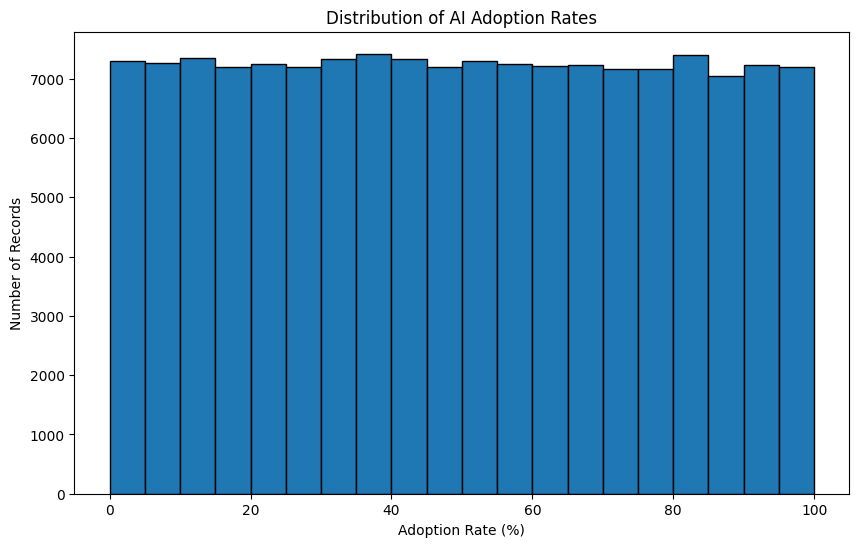

In [88]:
#- Adoption-rate histogram.

plt.figure(figsize = (10, 6))

plt.hist(AI_df["adoption_rate"], bins = 20, edgecolor= "black")

plt.title("Distribution of AI Adoption Rates")
plt.xlabel("Adoption Rate (%)")
plt.ylabel("Number of Records")

plt.show()

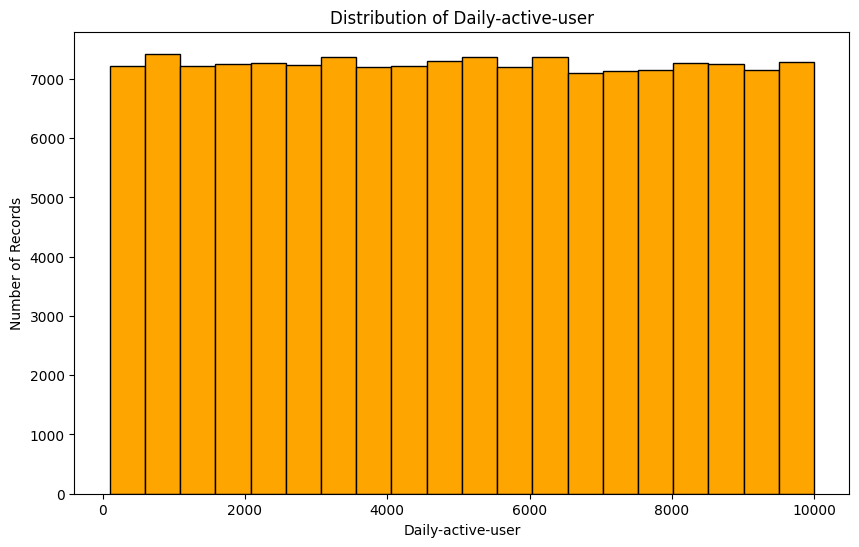

In [89]:
#Daily-active-user histogram.

plt.figure(figsize = (10, 6))

plt.hist(AI_df["daily_active_users"], bins = 20, color="orange" ,edgecolor= "black")

plt.title("Distribution of Daily-active-user")
plt.xlabel("Daily-active-user")
plt.ylabel("Number of Records")

plt.show()


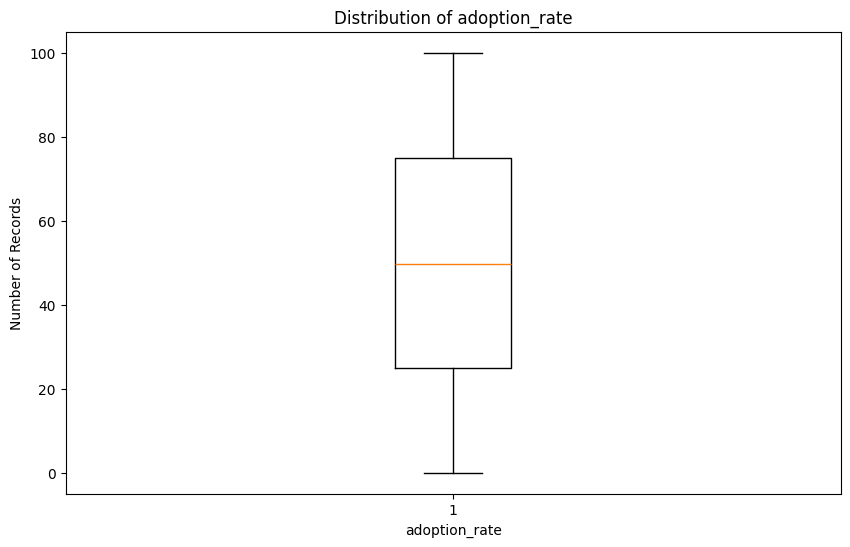

In [90]:
#Adoption-rate boxplot.

plt.figure(figsize = (10, 6))

plt.boxplot(AI_df["adoption_rate"])

plt.title("Distribution of adoption_rate")
plt.xlabel("adoption_rate")
plt.ylabel("Number of Records")

plt.show()


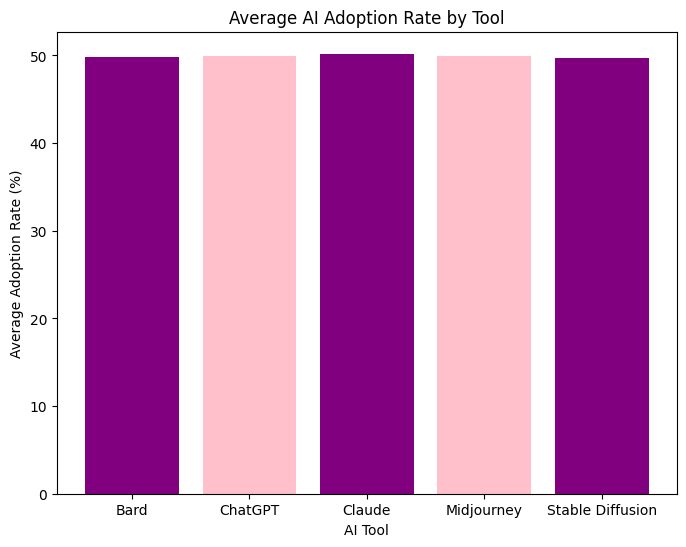

In [91]:
#Average adoption by AI tool.
plt.figure(figsize=(8, 6))

plt.bar(
    AI_tool_analysis.index,  
    AI_tool_analysis["avg_adoption_rate"], 
    color=["purple", "pink"])

plt.xlabel("AI Tool")
plt.ylabel("Average Adoption Rate (%)")
plt.title("Average AI Adoption Rate by Tool")

plt.show()


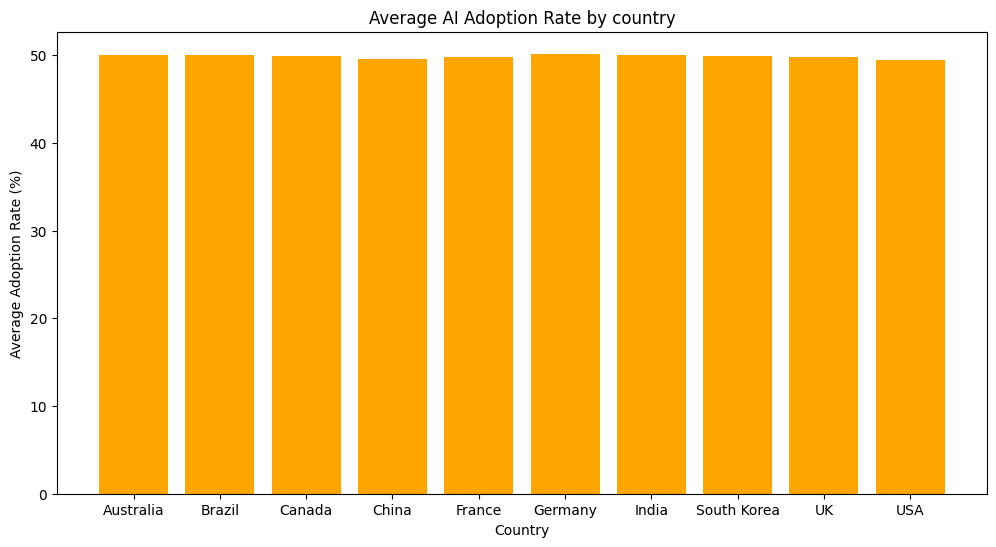

In [92]:
#Average adoption by country.
plt.figure(figsize=(12, 6))

plt.bar(
    Country_analysis.index, 
    Country_analysis["avg_adoption_rate"],
    color=["orange"])

plt.xlabel("Country")
plt.ylabel("Average Adoption Rate (%)")
plt.title("Average AI Adoption Rate by country")

plt.show()

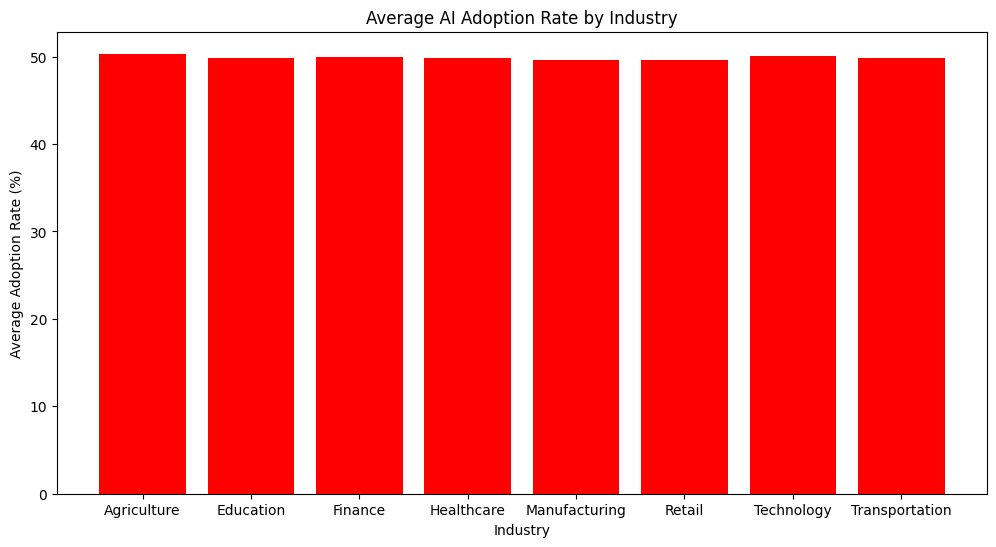

In [93]:
#Average adoption by Industry.
plt.figure(figsize=(12, 6))

plt.bar(
    Industry_analysis.index, 
    Industry_analysis["avg_adoption_rate"],
    color=["red"])

plt.xlabel("Industry")
plt.ylabel("Average Adoption Rate (%)")
plt.title("Average AI Adoption Rate by Industry")

plt.show()

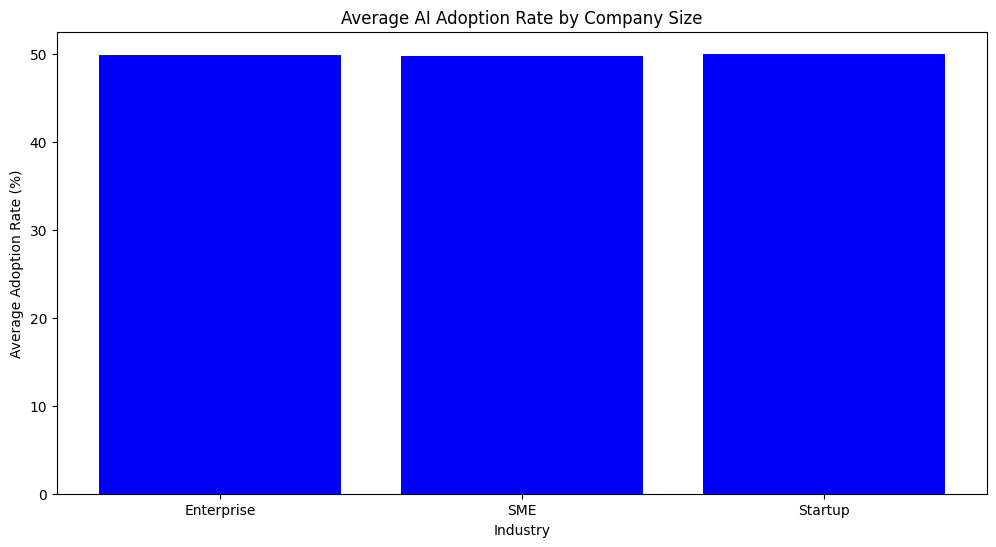

In [94]:
#Average adoption by Company Size.
plt.figure(figsize=(12, 6))

plt.bar(
    company_size_analysis.index, 
    company_size_analysis["avg_adoption_rate"],
    color=["blue"])

plt.xlabel("Industry")
plt.ylabel("Average Adoption Rate (%)")
plt.title("Average AI Adoption Rate by Company Size")

plt.show()

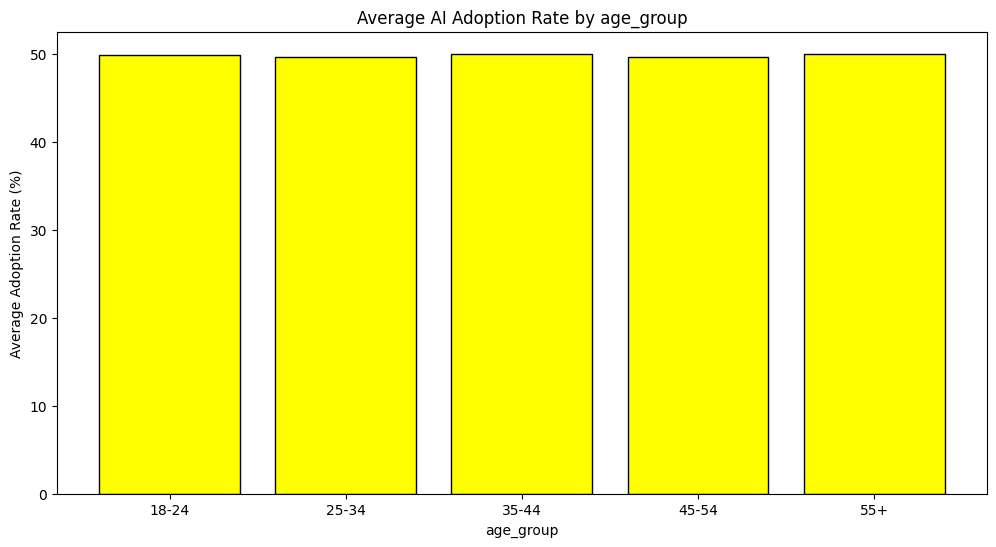

In [95]:
#Average adoption by Age Group.
plt.figure(figsize=(12, 6))

plt.bar(
    age_group_analysis.index, 
    age_group_analysis["avg_adoption_rate"],
    color=["yellow"],
    edgecolor= "black"
)

plt.xlabel("age_group")
plt.ylabel("Average Adoption Rate (%)")
plt.title("Average AI Adoption Rate by age_group")

plt.show()

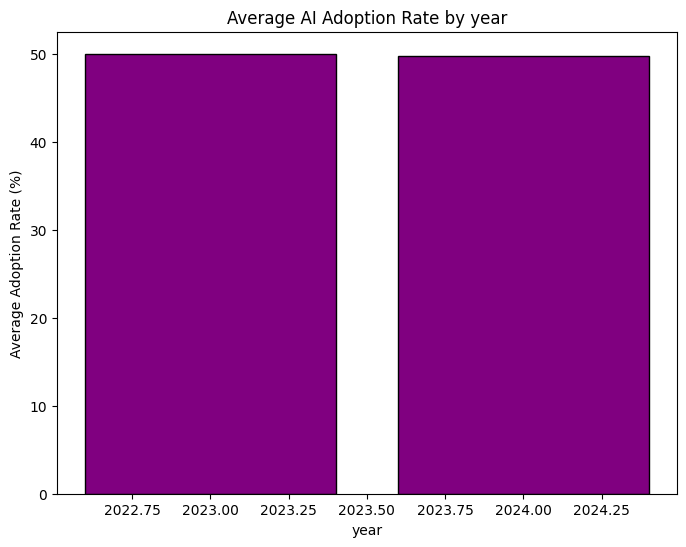

In [96]:
# Average adoption by year
plt.figure(figsize=(8, 6))

plt.bar(
    year_analysis.index, 
    year_analysis["avg_adoption_rate"],
    color=["purple"],
    edgecolor= "black"
)

plt.xlabel("year")
plt.ylabel("Average Adoption Rate (%)")
plt.title("Average AI Adoption Rate by year")

plt.show()

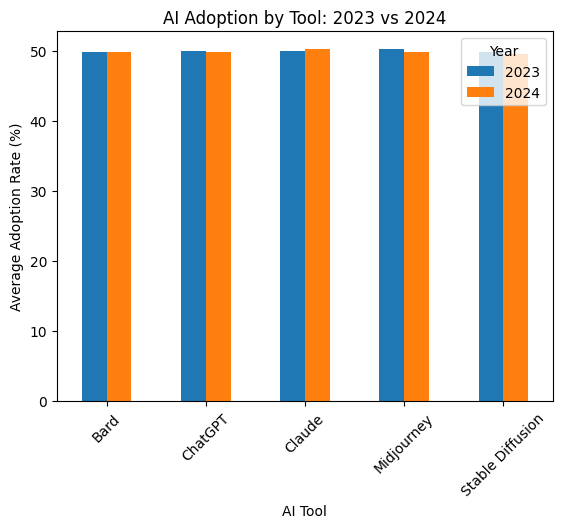

In [101]:
#2023 versus 2024 adoption by AI tool.
AI_tool_year.plot(
    kind="bar",
    figsize=(10, 6),
    color=["purple", "orange"]
)

plt.xlabel("AI Tool")
plt.ylabel("Average Adoption Rate (%)")
plt.title("AI Adoption by Tool: 2023 vs 2024")

plt.xticks(rotation=45)
plt.legend(title="Year")

plt.show()

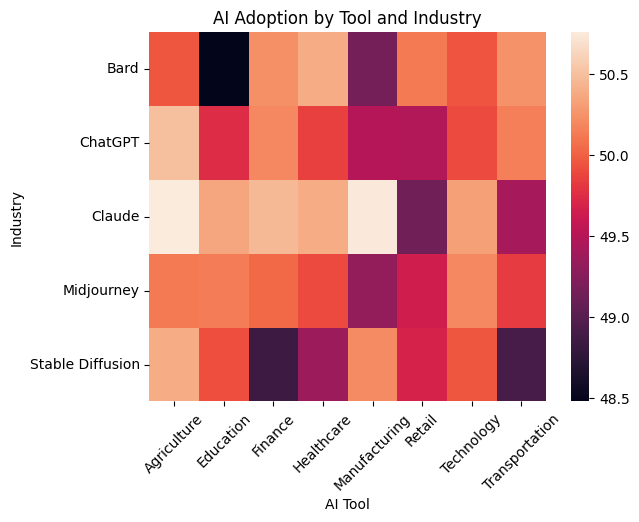

In [104]:
#AI tool × industry heatmap.

AI_Tool_industry = AI_df.groupby(
    ["ai_tool", "industry"]
)["adoption_rate"].mean().unstack()

sns.heatmap(
    AI_Tool_industry,
)

figsize=(12, 6),
color=["purple", "orange"]

plt.xlabel("AI Tool")
plt.ylabel("Industry")
plt.title("AI Adoption by Tool and Industry")

plt.xticks(rotation=45)
plt.show()

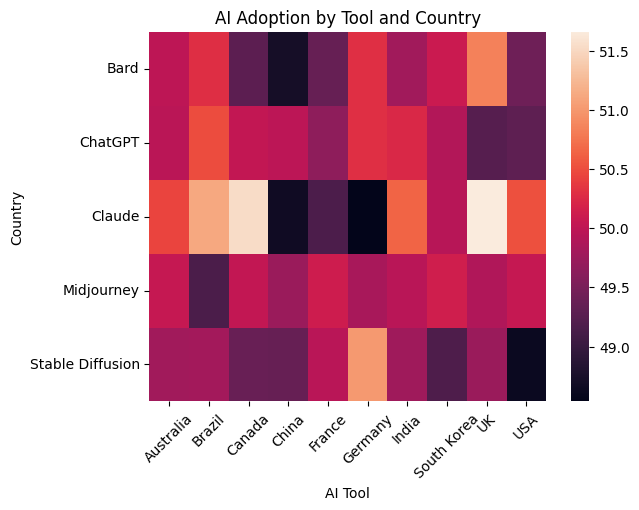

In [107]:
#AI tool × Country heatmap.

AI_Tool_Country = AI_df.groupby(
    ["ai_tool", "country"]
)["adoption_rate"].mean().unstack()

sns.heatmap(
    AI_Tool_Country,
)

figsize=(12, 6),
color=["blue", "green"]

plt.xlabel("AI Tool")
plt.ylabel("Country")
plt.title("AI Adoption by Tool and Country")

plt.xticks(rotation=45)
plt.show()

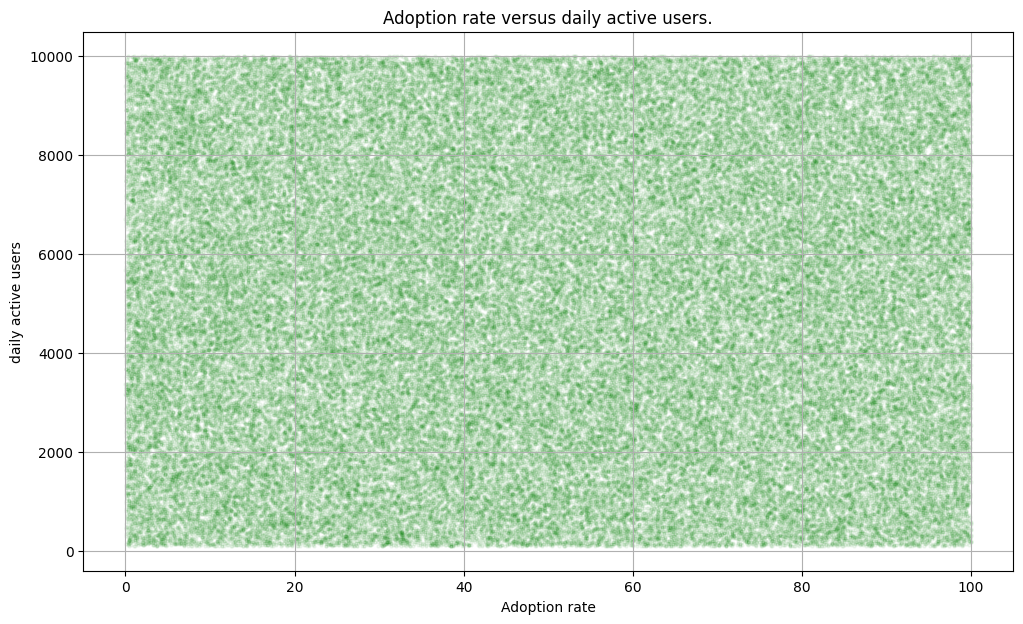

In [119]:
#Adoption rate versus daily active users scatter plot.

plt.figure(figsize=(12, 7))

plt.scatter(
    AI_df["adoption_rate"],
    AI_df["daily_active_users"],
    color =  "green",
    alpha=0.05,
    s=5
)

plt.xlabel("Adoption rate")
plt.ylabel("daily active users")
plt.title("Adoption rate versus daily active users.")

plt.grid(True)

plt.show()

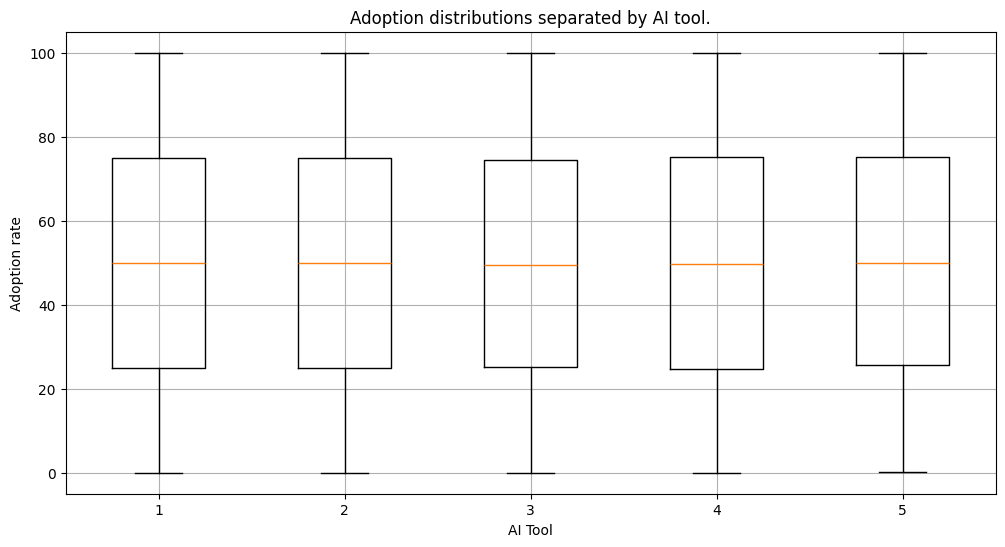

In [118]:
#Adoption distributions separated by AI tool.

plt.figure(figsize=(12, 6))

AI_tools = AI_df["ai_tool"].unique()

adoption_data = [
    AI_df[AI_df["ai_tool"] == tool]["adoption_rate"]
    for tool in AI_tools
]
plt.boxplot(adoption_data)

plt.ylabel("Adoption rate")
plt.xlabel("AI Tool")
plt.title("Adoption distributions separated by AI tool.")

plt.grid(True)

plt.show()

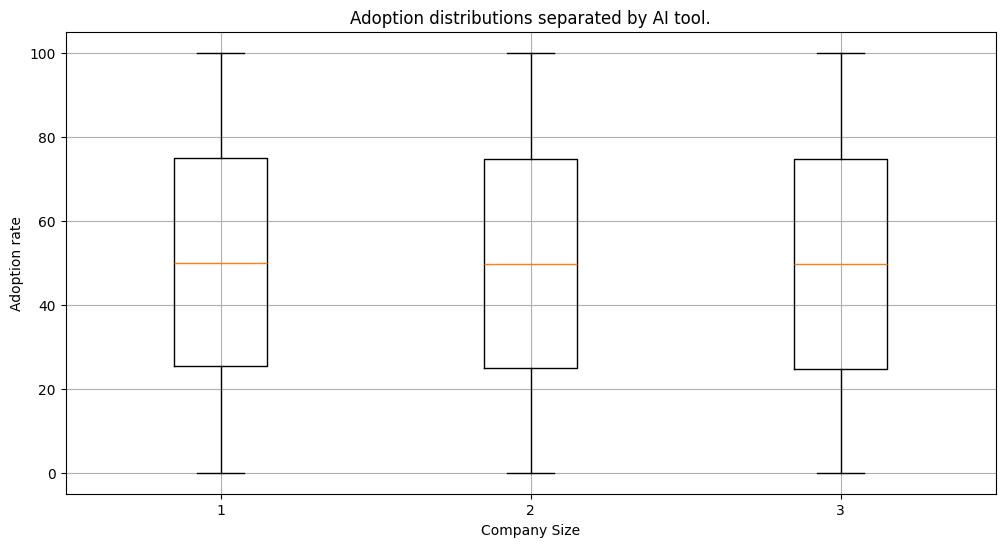

In [121]:
#Adoption distributions separated by company size.

plt.figure(figsize=(12, 6))

AI_tools = AI_df["company_size"].unique()

adoption_data = [
    AI_df[AI_df["company_size"] == tool]["adoption_rate"]
    for tool in AI_tools
]
plt.boxplot(adoption_data)

plt.ylabel("Adoption rate")
plt.xlabel("Company Size")
plt.title("Adoption distributions separated by AI tool.")

plt.grid(True)

plt.show()

### 1. Which AI tool has the highest average adoption?

Claude has the highest average adoption rate at **50.20%**, followed by ChatGPT at 49.91% and Midjourney at 49.90%. However, the differences between these tools are relatively small.

### 2. Which country has the highest average adoption?

Germany has the highest average adoption rate at **50.18%**, followed by India at 50.06% and Australia at 49.99%. The differences between countries are minimal.

### 3. Which industry has the highest average adoption?

Agriculture has the highest average adoption rate at **50.33%**, followed by Technology at 50.02% and Finance at 49.96%.

### 4. Which company size has the highest average adoption?

Startups have the highest average adoption rate at **50.04%**, followed by Enterprises at 49.84% and SMEs at 49.74%. The difference between the highest and lowest groups is approximately 0.29 percentage points.

### 5. Which age group has the highest average adoption?

The **55+ age group** has the highest average adoption rate at 50.04%, while the 25-34 age group has the lowest at 49.70%. The difference is only 0.34 percentage points.

### 6. Did average adoption differ between 2023 and 2024?

Yes. Average adoption decreased slightly from **50.02% in 2023 to 49.81% in 2024**, representing a decline of approximately 0.21 percentage points.

This is a small difference, and the dataset alone does not establish why it occurred.

### 7. Which AI tool changed the most between the two years?

Midjourney experienced the largest absolute change, with its average adoption rate decreasing by approximately **0.46 percentage points** between 2023 and 2024.

Claude recorded the largest increase, at approximately 0.23 percentage points.

### 8. Which industry and AI tool combinations have the strongest adoption?

The three combinations with the highest average adoption rates are:

1. Claude in Agriculture: **50.76%**
2. Claude in Manufacturing: **50.75%**
3. ChatGPT in Agriculture: **50.50%**

These combinations have the highest observed averages, although their advantages over other combinations are small.

### 9. Is daily active users (DAU) strongly related to adoption rate?

No. The Pearson correlation between adoption rate and daily active users is approximately **0.0022**, which is extremely close to zero.

This indicates virtually no linear relationship between the two variables in the dataset. Higher daily active user counts do not consistently correspond to higher adoption rates.

### 10. Which variables appear most useful for explaining adoption?

Industry and country show slightly more variation in average adoption rates than the other categorical variables. However, their relationships with adoption rate are extremely weak.

AI tool, company size, age group, year, and daily active users also show very limited relationships with adoption. Based on the descriptive analysis, no individual variable provides a strong explanation of differences in adoption rates.

### Business Conclusion

The analysis shows that average AI adoption rates are very similar across tools, countries, industries, company sizes, and age groups. Claude has the highest average adoption among AI tools, Germany leads among countries, and Agriculture has the highest industry average. Startups and users aged 55+ also show slightly higher adoption rates.

Between 2023 and 2024, overall average adoption decreased marginally, while the relationship between adoption rate and daily active users remained negligible.

**The dataset does not reveal substantial adoption differences between the categories examined.** The next stage should use statistical testing to determine whether the observed differences are statistically significant and machine learning to assess whether combinations of variables can predict adoption rates more accurately.

These findings describe the uploaded dataset and should not be treated as representative of global AI adoption without verifying the dataset's source and sampling method.